# Exploring NetCDF Files

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4
import nc_time_axis

#### Minor Cleaning

In [5]:
#ds0 = xr.open_dataset("/scratch/alpine/dagr5998/MDF_2/sibchuk_set_0014/history/icepack.h.19750101.nc", decode_times=False)
#ds0

In [10]:
ds=xr.open_dataset("/scratch/alpine/dagr5998/MDF_2/sibchuk_set_0010/history/icepack.h.19750101.nc")
ds=ds.sel(ni=3) # We care about the full ITD ice simulation, other ones aren't necessary

## Relevant Variable Exploration

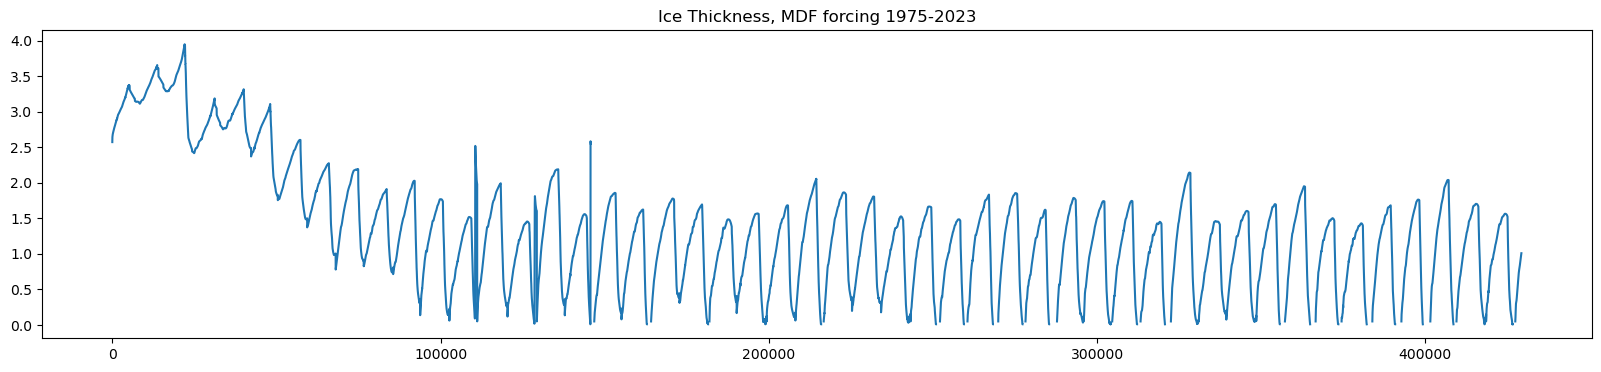

In [11]:
plt.figure(figsize=(20,4))
plt.plot(ds["vice"]/ds["aice"])
plt.title("Ice Thickness, MDF forcing 1975-2023")
plt.show()

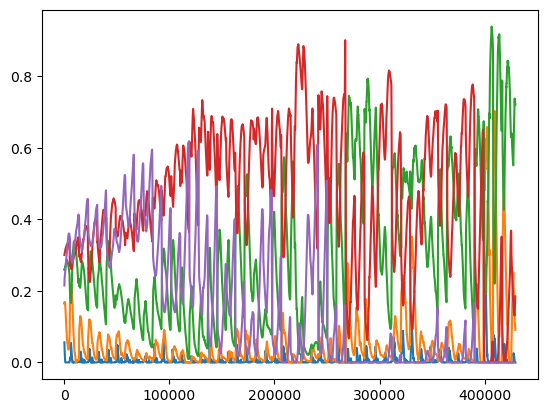

In [3]:
plt.plot(ds["aicen"])

### Area and Volume of Snow and Ice

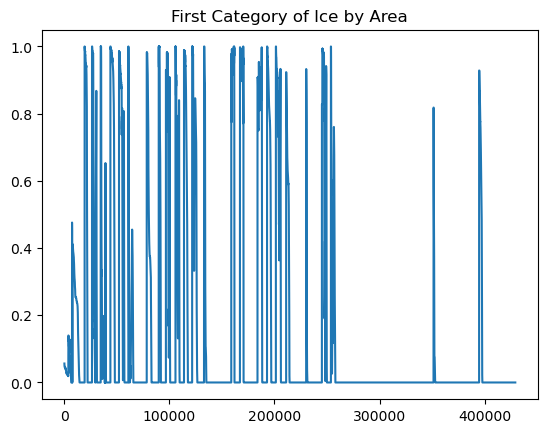

In [5]:
plt.plot(ds["aicen"].sel(ncat=1))
plt.title("First Category of Ice by Area")
plt.show()

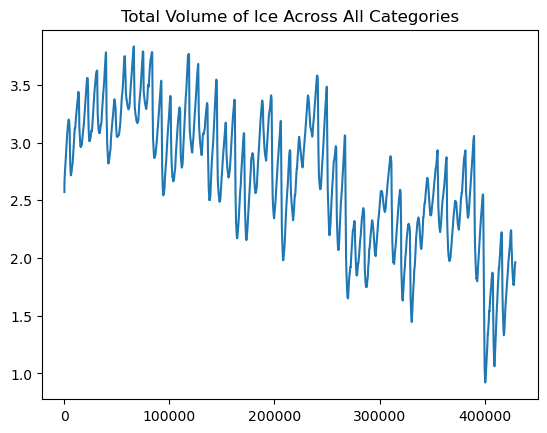

In [4]:
plt.plot(ds["vice"])
plt.title("Total Volume of Ice Across All Categories")
plt.show()

Note that aice, vice, vsno, are all redundant and can be derived from aicen, vicen, and vsnon

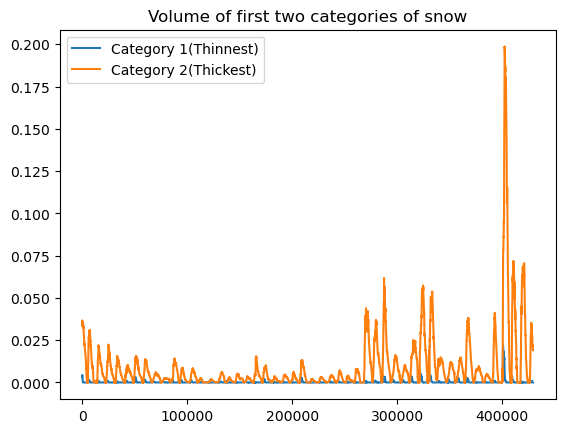

In [5]:
plt.plot(ds["vsnon"].sel(ncat=1), label="Category 1(Thinnest)")
plt.plot(ds["vsnon"].sel(ncat=2), label="Category 2(Thickest)")
plt.legend()
plt.title("Volume of first two categories of snow")
plt.show()

Note that in the default indexing, category 1 is the thinnest for snow/ice and it gets progressively thicker.

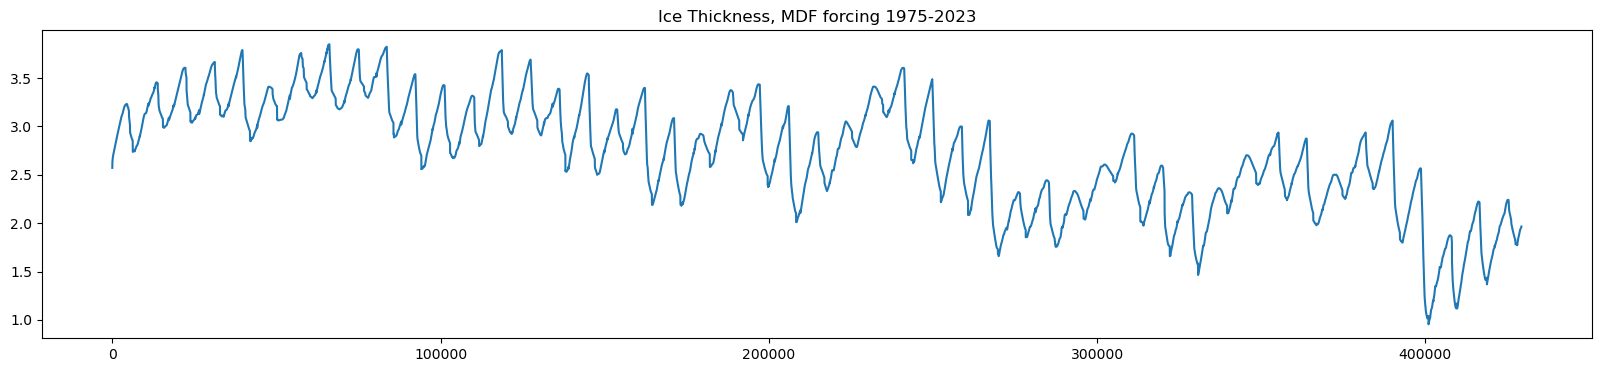

In [6]:
plt.figure(figsize=(20,4))
plt.plot(ds["vice"]/ds["aice"])
plt.title("Ice Thickness, MDF forcing 1975-2023")
plt.show()

### Other Variables

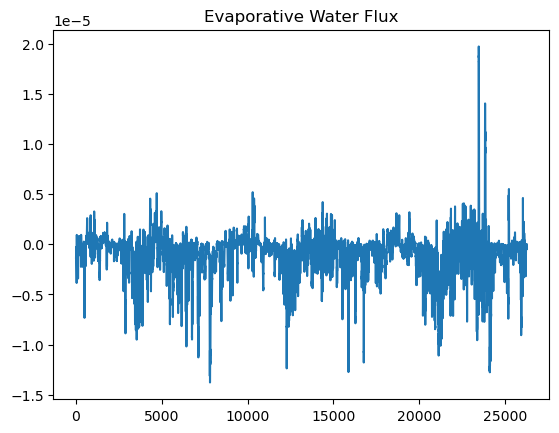

In [9]:
plt.plot(ds["evap"])
plt.title("Evaporative Water Flux")
plt.show()

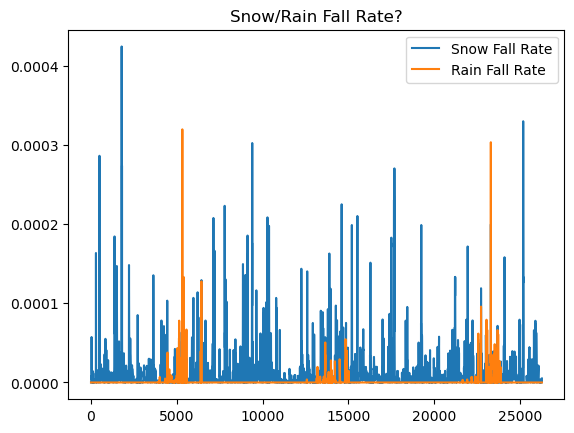

In [10]:
plt.plot(ds["fsnow"], label = "Snow Fall Rate")
plt.plot(ds["frain"], label = "Rain Fall Rate")
plt.title("Snow/Rain Fall Rate?")
plt.legend()
plt.show()

| Variable | Definition |
|---|---|
| frazil | Frazil ice growth  |
| fswabs | Total absorbed solar flux |
| fsw | Incoming shortwave|
| flw| Incoming longwave radiation |
| flwout | Outgoing longwave radiation |
| fsens | Sensible heat flux |
| fsurf | Net surface heat flux  |
| flat | Latent heat flux |
| Tair | Air temperature |
| Qa | Specific humidity |
| fcondtop | Conductive heat flux at the top surface |
| meltt | Surface ice melt |
| meltb | Basal ice melt |
| meltl | Lateral ice melt |
| melts | Snow melt|
| snoice | Snow-ice formation |
| dsnow |Change in snow thickness |
| congel | Basal ice growth|
| sst | Sea surface temperature|
| sss | Sea surface salinity |
| Tf | Freezing temperature |
| fhocn | Net heat flux to the ocean|

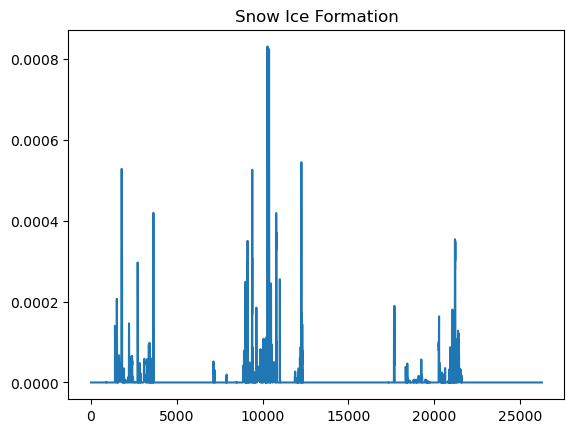

In [11]:
plt.plot(ds["snoice"])
plt.title("Snow Ice Formation")
plt.show()

## Tracers
From the run log:
```
 (icepack_write_tracer_indices):
   nt_Tsfc =            1
   nt_qice =            2
   nt_qsno =           10
   nt_sice =           13
   nt_alvl =           21
   nt_vlvl =           22
   nt_apnd =           23
   nt_hpnd =           24
   nt_ipnd =           25
```

In [12]:
#ds

Note that Fortran starts at 1, if we use `.sel` then the indicies will match. Also, trcrn is the variable and ntrcr is the dimension.

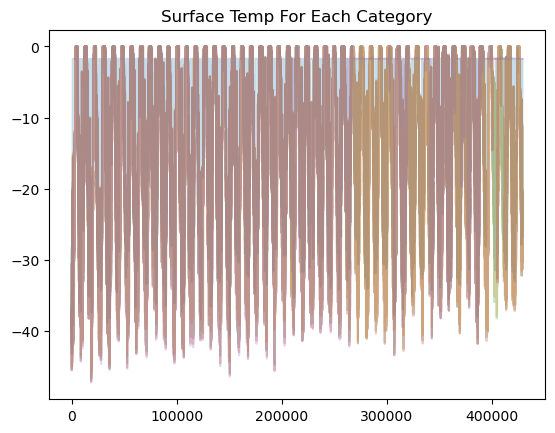

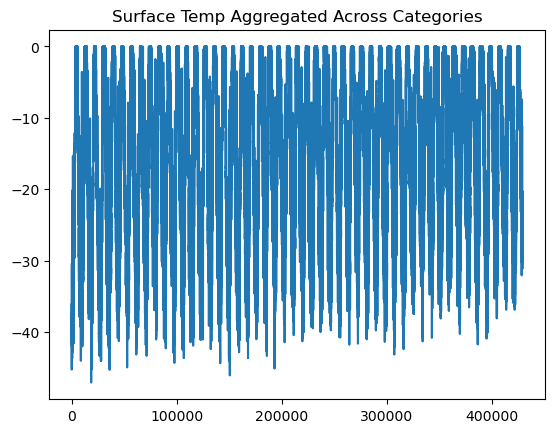

In [12]:
plt.plot(ds.sel(ntrcr=1)["trcrn"], alpha=.25)
plt.title("Surface Temp For Each Category")
plt.show()
plt.plot(ds.sel(ntrcr=1)["trcr"])
plt.title("Surface Temp Aggregated Across Categories")
plt.show()

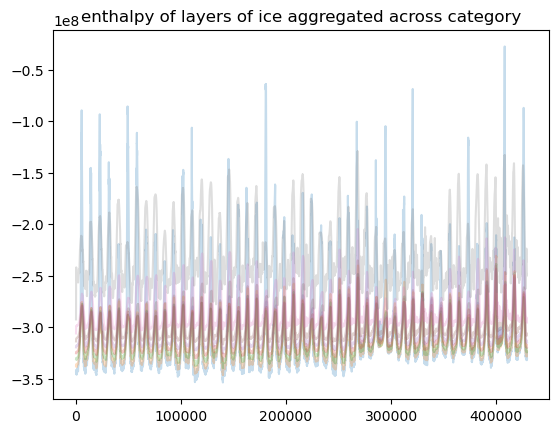

In [13]:
for i in range (2,10):
    plt.plot(ds.sel(ntrcr=i)["trcr"], alpha=.25)
plt.title("enthalpy of layers of ice aggregated across category")
plt.show()

Note that when we are training the model we will use the `trcrn` version of all of the variables, this is the pre-aggregated version (which provides no new info)

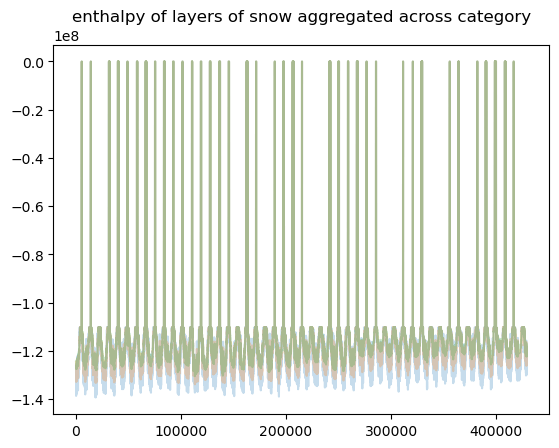

In [14]:
for i in range (10,13):
    plt.plot(ds.sel(ntrcr=i)["trcr"], alpha=.25)
plt.title("enthalpy of layers of snow aggregated across category")
plt.show()

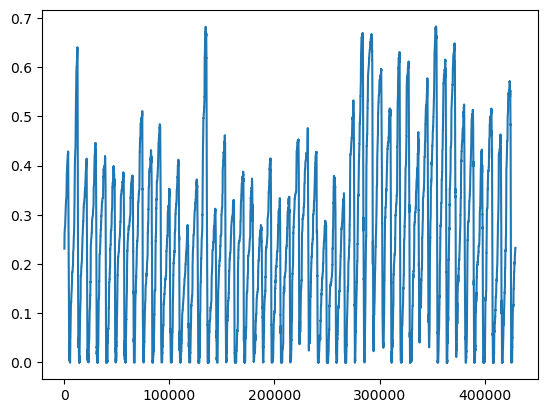

In [15]:
plt.plot(ds["vsno"])

Weird blip, comes from 0 vsno

21
22


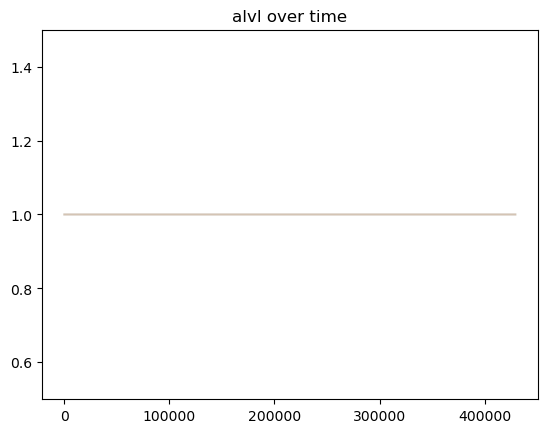

In [7]:
for i in range (21,23):
    plt.plot(ds.sel(ntrcr=i)["trcr"], alpha=.25)
    print(i)
plt.ylim(0.5,1.5)
plt.title("alvl over time")
plt.show()

In [8]:
print(ds.sel(ntrcr=21)["trcr"].max()-ds.sel(ntrcr=21)["trcr"].min())

<xarray.DataArray 'trcr' ()> Size: 8B
array(3.06532577e-13)
Coordinates:
    ni       int32 4B 3
    ntrcr    int32 4B 21


We would expect this to be 0, this is a ridging parameter.

## Dropped Variables

| Dropped Variable | Definition                | Notes|
|----------|---------------------------|------|
|aice     | area of ice (total)       | redundant|
|vice     | volume of ice (total)       | redundant|
|vsno     | volume of snow (total)       | redundant|
|trcr*    | Aggregated versions of trcrn*|redundant|
|uvel/vvel | x/y velocity of ice| drop, always 0 |
|divu | velocity divergence|drop, always 0 |
|shear | strain rate|drop, always 0 |
|strength| compressive ice strength| drop, always 0 |
|pnd_* |melt pond variables|out of scope?|
|last 3 tracers|melt pond variables|out of scope?|
|nt_alvl & nt_vlvl (tracer 21 & 22| level ice area/vol| out of scope?|

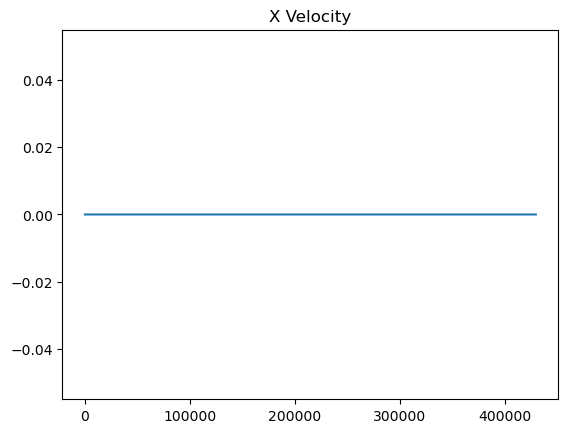

In [9]:
plt.plot(ds["uvel"])
plt.title("X Velocity")
plt.show()

We would expect this to be 0, this is a CICE parameter.

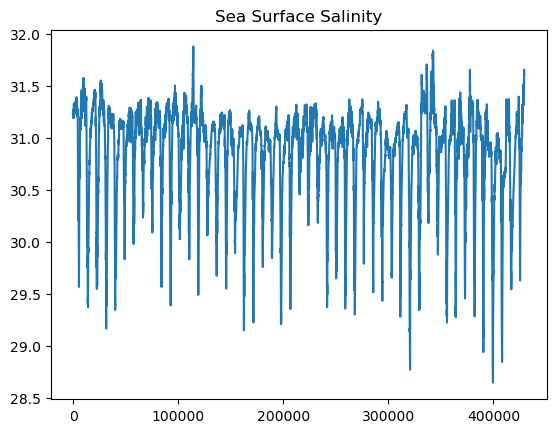

In [10]:
plt.plot(ds["sss"])
plt.title("Sea Surface Salinity")
plt.show()

We discussed a switch to fixed ocean forcing, the sss and qdp won't vary in that case.

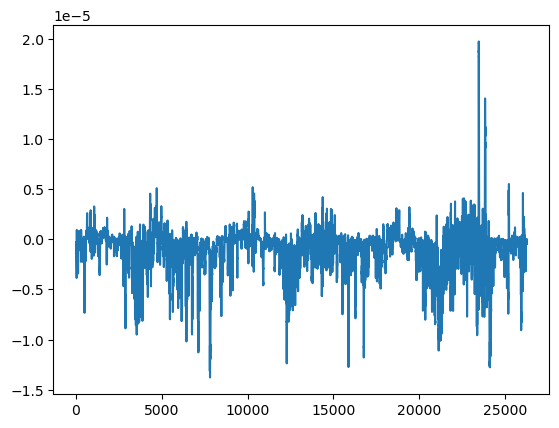

In [33]:
plt.plot(ds["evap"])

Keep Tracer Vars:
```
   nt_Tsfc =            1
   nt_qice =            2
   nt_qsno =           10
   nt_sice =           13
```

In [16]:
list(ds.data_vars)

['timestep',
 'date',
 'aice',
 'vice',
 'vsno',
 'uvel',
 'vvel',
 'divu',
 'shear',
 'strength',
 'evap',
 'fsnow',
 'frazil',
 'fswabs',
 'flw',
 'flwout',
 'fsens',
 'fsurf',
 'flat',
 'frain',
 'Tair',
 'Qa',
 'fsw',
 'fcondtop',
 'meltt',
 'meltb',
 'meltl',
 'snoice',
 'dsnow',
 'congel',
 'sst',
 'sss',
 'Tf',
 'fhocn',
 'melts',
 'apnd',
 'hpnd',
 'ipnd',
 'dpnd_flush',
 'dpnd_expon',
 'dpnd_freebd',
 'dpnd_initial',
 'dpnd_dlid',
 'dpnd_melt',
 'dpnd_ridge',
 'aicen',
 'vicen',
 'vsnon',
 'apndn',
 'hpndn',
 'ipndn',
 'dpnd_flushn',
 'dpnd_exponn',
 'dpnd_freebdn',
 'dpnd_initialn',
 'dpnd_dlidn',
 'trcr',
 'trcrn']